# Laboratorio 10 - Task 1: Grad-CAM y CAM

**Semilla:** 42  


## 0. Preparación

Se fijan las semillas y se cargan las dependencias. El notebook guarda las figuras en `results/task1/`.

In [1]:
from pathlib import Path
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision.models import ResNet18_Weights, resnet18
from torchvision.transforms import functional as TF

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
IMAGE_DIR = PROJECT_ROOT / 'data' / 'images'
RESULTS_DIR = PROJECT_ROOT / 'results' / 'task1'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print(f'Semilla: {SEED} | Dispositivo: {DEVICE} | Raíz: {PROJECT_ROOT}')

Semilla: 42 | Dispositivo: cpu | Raíz: c:\Users\richi\Documents\2026_S2_Local\Deep-Learning


## 1.1 Modelo, preprocesamiento e imágenes

El preprocesamiento replica el requerido: lado corto a 256, recorte central 224 x 224 y normalización de ImageNet. La función devuelve también la imagen RGB ya recortada para visualizar mapas y definir el recuadro.

In [2]:
WEIGHTS = ResNet18_Weights.IMAGENET1K_V1
model = resnet18(weights=WEIGHTS).to(DEVICE).eval()
CLASS_NAMES = WEIGHTS.meta['categories']
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

def preprocess_image(path):
    image = Image.open(path).convert('RGB')
    image_224 = TF.center_crop(TF.resize(image, 256), [224, 224])
    rgb = TF.to_tensor(image_224)
    normalized = (rgb - MEAN) / STD
    return image_224, rgb, normalized.unsqueeze(0).to(DEVICE)

def predict_top5(input_tensor):
    with torch.no_grad():
        logits = model(input_tensor)
        probs = logits.softmax(dim=1)[0]
    values, indices = probs.topk(5)
    table = pd.DataFrame({
        'class_index': indices.cpu().numpy(),
        'class_name': [CLASS_NAMES[i] for i in indices.cpu().tolist()],
        'probability': values.cpu().numpy(),
    })
    return logits, table

IMAGES = {
    'a': IMAGE_DIR / 'a_objeto_claro.jpg',
    'b': IMAGE_DIR / 'b_dos_objetos.jpg',
    'c': IMAGE_DIR / 'c_contexto_enganoso.jpg',
}
SOURCES = {
    'a': 'a_objeto_claro.jpg',
    'b': 'b_dos_objetos.jpg',
    'c': 'c_contexto_enganoso.jpg',
}
SECOND_CLASS_B = 'tabby'  
BBOX_C = (0, 80, 223, 208)  

missing = [str(path) for path in IMAGES.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Faltan las imágenes:\n' + '\n'.join(missing))

In [3]:
loaded = {}
prediction_rows = []
for key, path in IMAGES.items():
    image_224, rgb, input_tensor = preprocess_image(path)
    logits, top5 = predict_top5(input_tensor)
    loaded[key] = {'image': image_224, 'rgb': rgb, 'input': input_tensor, 'logits': logits}
    display(top5.style.format({'probability': '{:.6f}'}).set_caption(f'Imagen ({key}) - {SOURCES[key]}'))
    for rank, row in top5.reset_index(drop=True).iterrows():
        prediction_rows.append({'image': key, 'rank': rank + 1, **row.to_dict()})

predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv(RESULTS_DIR / 'task1_1_top5.csv', index=False)

,class_index,class_name,probability
0,235,German shepherd,0.976751
1,255,Leonberg,0.010374
2,225,malinois,0.008180
3,227,kelpie,0.001212
4,244,Tibetan mastiff,0.000539


,class_index,class_name,probability
0,235,German shepherd,0.401887
1,281,tabby,0.108870
2,285,Egyptian cat,0.071321
3,588,hamper,0.032350
4,248,Eskimo dog,0.024935


,class_index,class_name,probability
0,954,banana,0.755744
1,945,bell pepper,0.038470
2,942,butternut squash,0.034780
3,502,clog,0.031685
4,587,hammer,0.011993


## Respuesta 1.1

Se utilizó el modelo **ResNet-18 preentrenado con ImageNet** en modo de evaluación. Cada imagen fue preprocesada mediante redimensión a 256 píxeles en el lado corto, recorte central de **224 × 224 píxeles** y normalización utilizando la media y desviación estándar de ImageNet indicadas en el laboratorio.

### Imagen (a)

La imagen (a) contiene un **German shepherd** como objeto principal, centrado y claramente visible.

| Posición | Clase predicha | Probabilidad |
|---|---|---:|
| 1 | German shepherd | 97.68% |
| 2 | Leonberg | 1.04% |
| 3 | malinois | 0.82% |
| 4 | kelpie | 0.12% |
| 5 | Tibetan mastiff | 0.05% |

**Fuente:** Magnific, "Dog is sitting, white background, with black brown face", foto premium ID 369849084 (<https://www.magnific.com/premium-photo/dog-is-sitting-white-background-with-black-brown-face_369849084.htm>). Archivo local: `data/images/a_objeto_claro.jpg`.

---

### Imagen (b)

La imagen (b) contiene dos objetos de clases diferentes: un **perro** y un **gato**. La clase con mayor probabilidad asignada por ResNet-18 fue **German shepherd**.

| Posición | Clase predicha | Probabilidad |
|---|---|---:|
| 1 | German shepherd | 40.19% |
| 2 | tabby | 10.89% |
| 3 | Egyptian cat | 7.13% |
| 4 | hamper | 3.24% |
| 5 | Eskimo dog | 2.49% |

**Fuente:** Vecteezy, "Happy dog and cat that looking at the camera together isolated on white background", de Adiroot Komsawart, ID 47006768, licencia gratuita con atribución (<https://www.vecteezy.com/photo/47006768-happy-dog-and-cat-that-looking-at-the-camera-together-isolated-on-white-background>). Archivo local: `data/images/b_dos_objetos.jpg`.

---

### Imagen (c)

La imagen (c) contiene una **banana colocada sobre una computadora portátil**, utilizando un contexto menos habitual para el objeto. La clase con mayor probabilidad obtenida fue **banana**.

| Posición | Clase predicha | Probabilidad |
|---|---|---:|
| 1 | banana | 75.57% |
| 2 | bell pepper | 3.85% |
| 3 | butternut squash | 3.48% |
| 4 | clog | 3.17% |
| 5 | hammer | 1.20% |

**Fuente:** Dreamstime, "Banana sobre la mesa cerca del ordenador con un ratón de refrigerio", ID 293587325 (<https://es.dreamstime.com/banana-sobre-la-mesa-cerca-del-ordenador-con-un-rat%C3%B3n-de-refrigerio-image293587325>); se usó la vista previa con marca de agua. Archivo local: `data/images/c_contexto_enganoso.jpg`.

Para esta imagen se definió además el recuadro que encierra el objeto sobre la imagen procesada de **224 × 224 píxeles**:

`BBOX_C = (x1, y1, x2, y2) = (0, 80, 223, 208)`

donde `(x1, y1)` corresponde a la esquina superior izquierda y `(x2, y2)` a la esquina inferior derecha del recuadro.

## 1.2 Grad-CAM desde cero

El hook de avance captura las activaciones $A^k$ de `layer4`; el hook de retroceso captura $\partial y^c / \partial A^k$. Se retropropaga el **logit** de la clase. Luego $\alpha_k^c$ es el promedio espacial del gradiente y $L^c = \operatorname{ReLU}(\sum_k \alpha_k^c A^k)$.

In [4]:
def minmax(x, eps=1e-12):
    return (x - x.min()) / (x.max() - x.min()).clamp_min(eps)

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        self.handles = [
            target_layer.register_forward_hook(self._save_activations),
            target_layer.register_full_backward_hook(self._save_gradients),
        ]

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, input_tensor, class_index=None):
        self.model.zero_grad(set_to_none=True)
        logits = self.model(input_tensor)
        if class_index is None:
            class_index = int(logits.argmax(dim=1).item())
        logits[0, class_index].backward()
        alpha = self.gradients.mean(dim=(2, 3), keepdim=True)
        raw_7 = (alpha * self.activations).sum(dim=1)[0]
        relu_7 = F.relu(raw_7)
        normalized_7 = minmax(relu_7)
        normalized_224 = F.interpolate(
            normalized_7[None, None], size=(224, 224), mode='bilinear', align_corners=False
        )[0, 0]
        return {
            'class_index': class_index, 'logits': logits.detach(),
            'activations': self.activations[0], 'gradients': self.gradients[0],
            'alpha': alpha[0, :, 0, 0], 'raw_7': raw_7,
            'normalized_7': normalized_7, 'normalized_224': normalized_224,
        }

    def close(self):
        for handle in self.handles:
            handle.remove()

def resolve_class(value):
    if isinstance(value, int):
        return value
    if value not in CLASS_NAMES:
        raise ValueError('SECOND_CLASS_B debe ser un índice o un nombre exacto de CLASS_NAMES.')
    return CLASS_NAMES.index(value)

def plot_overlay(image, heatmap, title, output_name):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(image)
    ax.imshow(heatmap.detach().cpu(), cmap='jet', alpha=0.45, vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis('off')
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / output_name, dpi=180, bbox_inches='tight')
    plt.show()

gradcam = GradCAM(model, model.layer4)

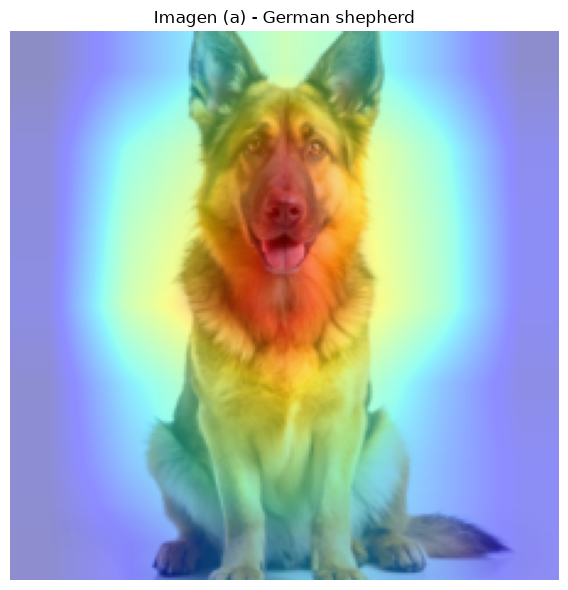

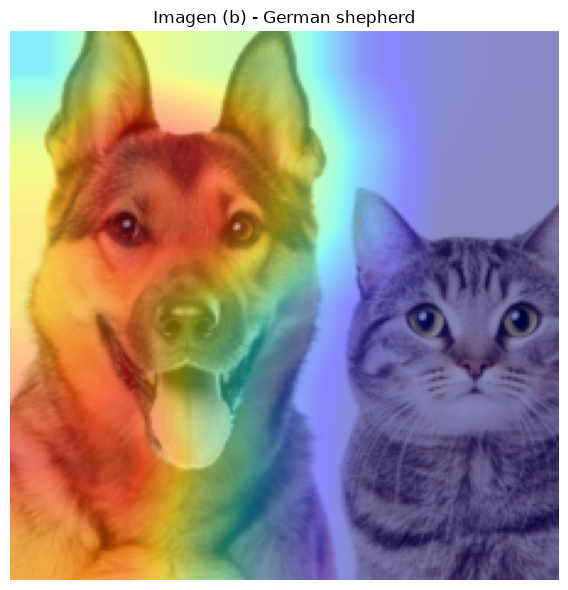

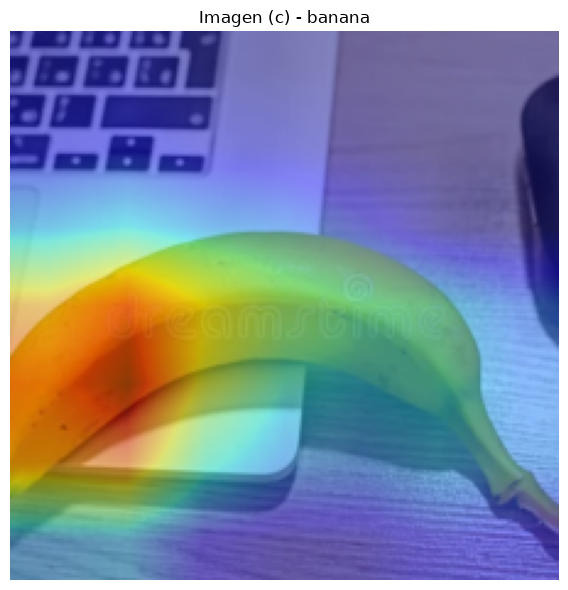

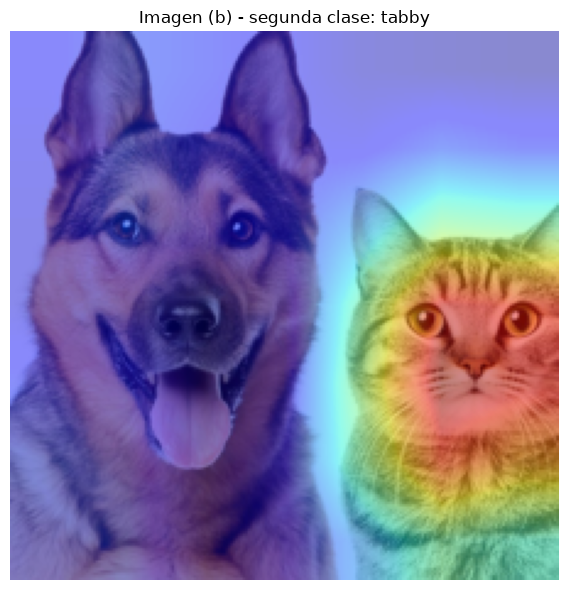

In [5]:
maps = {}
for key, item in loaded.items():
    result = gradcam(item['input'])
    maps[(key, 'top1')] = result
    class_name = CLASS_NAMES[result['class_index']]
    plot_overlay(item['image'], result['normalized_224'], f'Imagen ({key}) - {class_name}', f'task1_2_{key}_top1.png')

second_class_index = resolve_class(SECOND_CLASS_B)
maps[('b', 'second')] = gradcam(loaded['b']['input'], second_class_index)
plot_overlay(
    loaded['b']['image'], maps[('b', 'second')]['normalized_224'],
    f'Imagen (b) - segunda clase: {CLASS_NAMES[second_class_index]}',
    'task1_2_b_second_class.png',
)

**Respuesta 1.2:** 

En la imagen (a), correspondiente a la clase German shepherd, el mapa Grad-CAM concentra las activaciones más altas principalmente en la cabeza y el rostro del perro, especialmente alrededor del hocico, los ojos y la región superior del torso. Esto sugiere que el modelo utiliza características visuales propias del animal, como la forma de la cabeza, las orejas y el pelaje, para sustentar su clasificación. La activación disminuye hacia las patas y el fondo, por lo que la decisión parece depender principalmente del objeto y no del contexto.

En la imagen (b), para la clase German shepherd, la activación se concentra principalmente sobre el perro ubicado en el lado izquierdo, particularmente en su rostro, orejas y parte superior del cuerpo. El gato situado a la derecha presenta una activación considerablemente menor. Esto indica que, aunque ambos objetos aparecen simultáneamente en la imagen, el modelo logra localizar las regiones asociadas específicamente con la clase del perro.

Para la segunda clase de la imagen (b), **tabby**, las activaciones más altas se desplazan hacia la cabeza y el rostro del gato situado a la derecha, especialmente alrededor de los ojos y las orejas, mientras que la activación sobre el perro disminuye significativamente. El contraste entre `task1_2_b_top1.png` y `task1_2_b_second_class.png` muestra que Grad-CAM depende de la clase objetivo y no funciona únicamente como un detector genérico de objetos.

Finalmente, en la imagen (c), para la clase **banana**, las regiones de mayor activación aparecen principalmente sobre la parte izquierda y central de la fruta. El mapa suavizado también se extiende a una porción de la computadora y de la mesa, por lo que la visualización por sí sola no permite afirmar que el modelo use el contexto; esa hipótesis se contrasta cuantitativamente en la sección 1.4c.

En conjunto, los mapas de la imagen (b) concentran la evidencia de **German shepherd** en el perro y la de **tabby** en el gato. Esto aporta evidencia visual de que Grad-CAM discrimina entre clases; la separación se confirma numéricamente con el IoU calculado en la sección 1.4b.

## 1.3 CAM y verificaciones numéricas

Para ResNet-18, $M_{ij}^c = \sum_k w_k^c A_{ij}^k$. Como el pooling global promedia $Z=49$ posiciones, $y^c = \frac{1}{Z}\sum_{ij}M_{ij}^c+b_c$. Además, antes de ReLU y normalización, $ZL^c$ debe coincidir con $M^c$.

In [6]:
Z = 7 * 7
verification_rows = []
cam_maps = {}
for key in ['a', 'b', 'c']:
    gc = maps[(key, 'top1')]
    c = gc['class_index']
    weights_c = model.fc.weight[c].detach()
    bias_c = model.fc.bias[c].detach()
    cam_raw = (weights_c[:, None, None] * gc['activations']).sum(dim=0)
    cam_maps[key] = minmax(F.relu(cam_raw))
    reconstructed_logit = cam_raw.mean() + bias_c
    actual_logit = gc['logits'][0, c]
    raw_relation_error = (Z * gc['raw_7'] - cam_raw).abs().max()
    normalized_error = (gc['normalized_7'] - cam_maps[key]).abs().max()
    verification_rows.append({
        'image': key, 'class': CLASS_NAMES[c],
        'logit': actual_logit.item(),
        'cam_mean_plus_bias': reconstructed_logit.item(),
        'logit_abs_error': abs(actual_logit.item() - reconstructed_logit.item()),
        'max_abs_error_Z_gradcam_vs_cam': raw_relation_error.item(),
        'max_abs_error_normalized_maps': normalized_error.item(),
    })

verification_df = pd.DataFrame(verification_rows)
display(verification_df.style.format(precision=10))
verification_df.to_csv(RESULTS_DIR / 'task1_3_verification.csv', index=False)

,image,class,logit,cam_mean_plus_bias,logit_abs_error,max_abs_error_Z_gradcam_vs_cam,max_abs_error_normalized_maps
0,a,German shepherd,15.6764965057,15.6764974594,0.0000009537,0.0000076294,0.0000001192
1,b,German shepherd,9.4948616028,9.4948616028,0.0000000000,0.0000019073,0.0000001192
2,c,banana,11.4739151001,11.4739141464,0.0000009537,0.0000057220,0.0000001192


**Respuesta 1.3:**

| Imagen | Clase | Error absoluto del logit | Máx. error $|ZL^c-M^c|$ | Máx. error entre mapas normalizados |
|---|---|---:|---:|---:|
| (a) | German shepherd | $9.5367\times10^{-7}$ | $7.6294\times10^{-6}$ | $1.1921\times10^{-7}$ |
| (b) | German shepherd | $0$ | $1.9073\times10^{-6}$ | $1.1921\times10^{-7}$ |
| (c) | banana | $9.5367\times10^{-7}$ | $5.7220\times10^{-6}$ | $1.1921\times10^{-7}$ |

El logit reconstruido como $\operatorname{mean}(M^c)+b_c$ coincide con el logit directo: el peor error absoluto es $9.54\times10^{-7}$. Asimismo, la relación previa a ReLU y normalización, $ZL^c=M^c$ con $Z=49$, presenta un error máximo de $7.63\times10^{-6}$, y los mapas normalizados difieren como máximo en $1.19\times10^{-7}$. Todas estas discrepancias son del orden esperado por redondeo en `float32`, por lo que los resultados respaldan numéricamente la equivalencia teórica entre CAM y Grad-CAM para esta arquitectura.

## 1.4 Análisis cuantitativo

### 1.4a - Pesos de Grad-CAM frente a pesos de la capa final

In [7]:
gc_a = maps[('a', 'top1')]
c_a = gc_a['class_index']
w_over_z = model.fc.weight[c_a].detach() / Z
top_channels = model.fc.weight[c_a].detach().abs().topk(5).indices
alpha_rows = []
for channel in top_channels.tolist():
    expected = w_over_z[channel]
    observed = gc_a['alpha'][channel]
    alpha_rows.append({
        'channel': channel, 'alpha': observed.item(), 'w_over_Z': expected.item(),
        'relative_error': ((observed - expected).abs() / expected.abs().clamp_min(1e-12)).item(),
    })
alpha_df = pd.DataFrame(alpha_rows)
display(alpha_df.style.format(precision=12))
alpha_df.to_csv(RESULTS_DIR / 'task1_4a_alpha_vs_weights.csv', index=False)

,channel,alpha,w_over_Z,relative_error
0,173,0.005869080778,0.005869080778,0.000000000000
1,60,0.005781139247,0.005781139713,0.000000080548
2,83,0.005239364225,0.005239364225,0.000000000000
3,415,0.004152091686,0.004152091220,0.000000112151
4,271,0.003989937250,0.003989937250,0.000000000000


**Respuesta 1.4a:** después de `layer4`, ResNet-18 aplica global average pooling y la capa lineal. Para la clase $c$, $y^c=\sum_k w_k^c\left(\frac{1}{Z}\sum_{i,j}A_{ij}^k\right)+b_c$, de modo que $\partial y^c/\partial A_{ij}^k=w_k^c/Z$ es constante en las $Z=49$ posiciones. Al promediar espacialmente esos 49 gradientes en Grad-CAM se obtiene de nuevo $\alpha_k^c=w_k^c/Z$.

En los cinco canales con mayor $|w_k^c|$ de la imagen (a), los errores relativos fueron $0$, $8.05\times10^{-8}$, $0$, $1.12\times10^{-7}$ y $0$. Por tanto, `alpha` y `w_over_Z` coinciden hasta aproximadamente siete cifras decimales. Las pequeñas diferencias no indican una desviación del resultado teórico: provienen del orden de las operaciones y del redondeo de aritmética `float32`.

### 1.4b - Separación entre clases en la imagen (b)

In [8]:
def top_fraction_mask(heatmap, fraction=0.20):
    flat = heatmap.flatten()
    count = max(1, int(np.ceil(flat.numel() * fraction)))
    indices = flat.topk(count).indices
    mask = torch.zeros_like(flat, dtype=torch.bool)
    mask[indices] = True
    return mask.reshape_as(heatmap)

mask_top1 = top_fraction_mask(maps[('b', 'top1')]['normalized_224'])
mask_second = top_fraction_mask(maps[('b', 'second')]['normalized_224'])
intersection = (mask_top1 & mask_second).sum().item()
union = (mask_top1 | mask_second).sum().item()
iou = intersection / union
print(f'IoU del 20% superior: {iou:.6f} (intersección={intersection}, unión={union})')

IoU del 20% superior: 0.000000 (intersección=0, unión=20072)


**Respuesta 1.4b:** el IoU entre el 20% de mayor activación del mapa de **German shepherd** y el de **tabby** fue **0.000000**, con intersección de 0 píxeles y unión de 20,072 píxeles. En este ejemplo, las regiones más relevantes de ambos mapas no se superponen: el primero se concentra en el perro y el segundo en el gato. Esto constituye evidencia cuantitativa fuerte de que el mapa discrimina entre las dos clases.

Sin embargo, la localización original se calcula sobre una cuadrícula de solo $7\times7$. Cada celda representa aproximadamente $224/7=32$ píxeles por lado, y el mapa de $224\times224$ se obtiene por interpolación bilineal. Por ello, Grad-CAM distingue regiones amplias y objetos separados, pero no permite interpretar con precisión bordes finos ni atribuir significado independiente a cada píxel interpolado. En consecuencia, un objeto de menos de unos 32 píxeles ocupa una fracción de una sola celda, y dos objetos cuyos centros caen en la misma celda o en celdas vecinas reciben esencialmente el mismo valor: el mapa no puede separarlos. Aquí la separación funcionó porque el perro y el gato ocupan regiones distintas de varias celdas cada una.

### 1.4c - Masa dentro del objeto y prueba causal del fondo

,class,bbox,normalized_map_mass_inside_bbox,original_probability,probability_gray_outside_bbox,change_gray_minus_original
0,banana,"(0, 80, 223, 208)",0.861895,0.755744,0.756964,0.001221


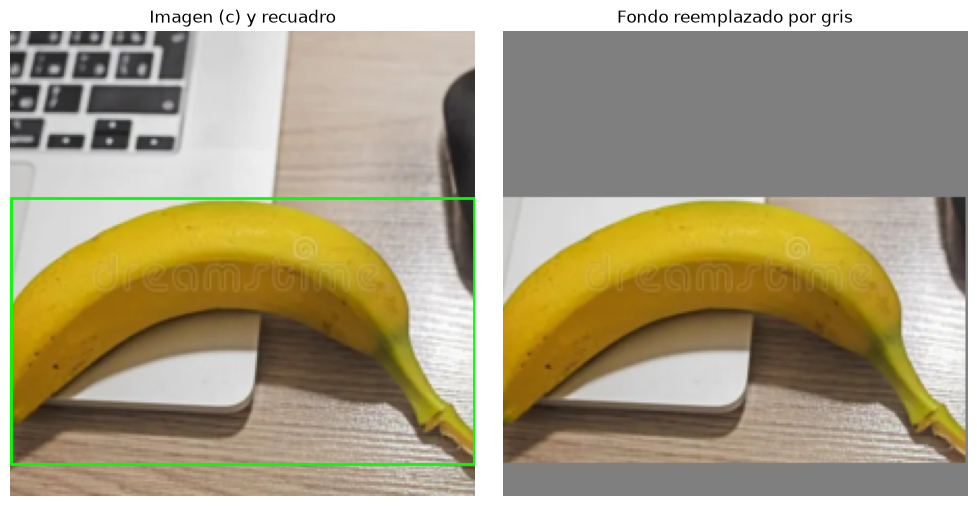

In [9]:
if BBOX_C is None:
    raise ValueError('Defina BBOX_C = (x_min, y_min, x_max, y_max) en la configuración.')
x_min, y_min, x_max, y_max = BBOX_C
if not (0 <= x_min < x_max <= 224 and 0 <= y_min < y_max <= 224):
    raise ValueError('BBOX_C debe estar dentro de 0..224 y tener área positiva.')

heatmap_c = maps[('c', 'top1')]['normalized_224']
inside_mass = heatmap_c[y_min:y_max, x_min:x_max].sum()
mass_fraction = (inside_mass / heatmap_c.sum().clamp_min(1e-12)).item()

rgb_c = loaded['c']['rgb'].clone()
gray_background = torch.full_like(rgb_c, 0.5)
gray_background[:, y_min:y_max, x_min:x_max] = rgb_c[:, y_min:y_max, x_min:x_max]
gray_input = ((gray_background - MEAN) / STD).unsqueeze(0).to(DEVICE)
class_c = maps[('c', 'top1')]['class_index']
with torch.no_grad():
    original_probability = model(loaded['c']['input']).softmax(1)[0, class_c].item()
    gray_probability = model(gray_input).softmax(1)[0, class_c].item()
probability_change = gray_probability - original_probability

causal_df = pd.DataFrame([{
    'class': CLASS_NAMES[class_c], 'bbox': BBOX_C,
    'normalized_map_mass_inside_bbox': mass_fraction,
    'original_probability': original_probability,
    'probability_gray_outside_bbox': gray_probability,
    'change_gray_minus_original': probability_change,
}])
display(causal_df.style.format(precision=6))
causal_df.to_csv(RESULTS_DIR / 'task1_4c_background_test.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(loaded['c']['image'])
axes[0].add_patch(plt.Rectangle((x_min, y_min), x_max-x_min, y_max-y_min, fill=False, edgecolor='lime', linewidth=2))
axes[0].set_title('Imagen (c) y recuadro')
axes[1].imshow(gray_background.permute(1, 2, 0))
axes[1].set_title('Fondo reemplazado por gris')
for ax in axes: ax.axis('off')
fig.tight_layout()
fig.savefig(RESULTS_DIR / 'task1_4c_causal_test.png', dpi=180, bbox_inches='tight')
plt.show()

**Respuesta 1.4c:** el recuadro `(0, 80, 223, 208)` contiene **0.861895**, es decir, **86.19%**, de la masa total del mapa Grad-CAM normalizado. Como el código recorta `[y_min:y_max, x_min:x_max]` con extremo exclusivo, la región evaluada mide $128\times223$ píxeles, el **56.89%** del área: esa es la masa que recibiría un mapa uniforme, y la concentración observada es **1.52 veces** esa referencia. Además, la probabilidad de **banana** fue **0.755744** (75.57%) en la imagen original y **0.756964** (75.70%) al reemplazar por gris todo lo exterior al recuadro. El cambio fue apenas **+0.001221**, equivalente a **+0.12 puntos porcentuales**.

Ambos resultados son consistentes con una decisión dominada por la región que contiene la banana: la mayor parte de la activación cae dentro del recuadro y eliminar la información externa no reduce la confianza. Por tanto, esta prueba no aporta evidencia de que el modelo explote un atajo contextual basado en el fondo; incluso se observa un aumento mínimo compatible con variación numérica o con la eliminación de elementos distractores. Como limitación, el recuadro es amplio e incluye parte de la computadora y de la mesa, de modo que la prueba descarta dependencia del fondo **exterior** al recuadro, pero no separa por completo la fruta del contexto que queda dentro de él.

In [10]:
gradcam.close()